<a href="https://colab.research.google.com/github/weagan/MAX-mojo/blob/main/cuda_vs_max_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CUDA (PyTorch) vs Modular MAX — LLM inference benchmark

Runs on **Google Colab** and **Kaggle**. No Modular API key is needed: MAX is installed from PyPI and runs locally.

**Flow**
1. Load secrets (optional `HF_TOKEN` for Hugging Face downloads / gated models)
2. **Part 1:** run the model with PyTorch + CUDA and record latency / throughput
3. Free the GPU, install MAX in an isolated virtualenv, start `max serve` locally
4. **Part 2:** run the identical benchmark against MAX
5. Compare in a table and charts

**Secrets setup (optional but recommended)**
- Colab: key icon in the left sidebar, add `HF_TOKEN`, enable *Notebook access*
- Kaggle: *Add-ons → Secrets*, add `HF_TOKEN`, attach it to the notebook
- Kaggle also needs **Internet: On** and a GPU accelerator

**GPU notes:** MAX supports a limited set of GPUs. Ampere or newer (A100, L4, A10, RTX 30/40, H100) is the safest choice. T4 may work; Kaggle's P100 (Pascal) is not supported by MAX, so Part 2 will fail there.

In [1]:
import os, sys, subprocess

def get_secret(name, default=None):
    """Read a secret from Colab, Kaggle, or environment variables (in that order)."""
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        v = UserSecretsClient().get_secret(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name, default)

PLATFORM = "colab" if "google.colab" in sys.modules else ("kaggle" if os.path.exists("/kaggle") else "other")
HF_TOKEN = get_secret("HF_TOKEN")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    os.environ["HUGGING_FACE_HUB_TOKEN"] = HF_TOKEN
print(f"Platform: {PLATFORM} | HF_TOKEN found: {bool(HF_TOKEN)}  (a token is only required for gated models)")

Platform: colab | HF_TOKEN found: True  (a token is only required for gated models)


In [2]:
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout or "NO GPU - enable a GPU runtime!")

Mon Oct 19 18:36:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# ---------------- Config ----------------
MODEL        = "Qwen/Qwen2.5-0.5B-Instruct"   # any model supported by BOTH transformers and MAX
                                              # e.g. "meta-llama/Llama-3.2-1B-Instruct" (gated: needs HF_TOKEN)
NEW_TOKENS   = 128      # tokens generated per request
BATCH        = 8        # concurrent requests for the throughput test
MAX_LEN      = 2048     # context length for MAX server
PORT         = 8000
DEVICE       = "cpu"    # Run MAX in CPU mode to avoid Tesla T4 architecture compilation failures

PROMPTS = [
    "Explain how a GPU executes a matrix multiplication, step by step.",
    "Write a short story about a robot learning to paint.",
    "What are the main differences between CPUs and GPUs?",
    "Summarize the causes of the French Revolution.",
    "Give me a Python function that checks if a string is a palindrome, and explain it.",
]

import torch
cc = torch.cuda.get_device_capability(0)
GPU_NAME = torch.cuda.get_device_name(0)
# For the CPU comparison, we will still display the available GPU
print(f"GPU available: {GPU_NAME} (sm_{cc[0]}{cc[1]}) | MAX configured to run on: {DEVICE.upper()}")

GPU available: Tesla T4 (sm_75) | MAX configured to run on: CPU


In [4]:
import statistics as st, time, json, gc

def run_suite(name, gen_fn):
    """
    gen_fn(prompts: list[str], max_new: int) -> (wall_seconds, total_new_tokens)
    Identical benchmark for both backends.
    """
    print(f"\n=== {name} ===")
    for _ in range(2): gen_fn(PROMPTS[:1], 16)                      # warmup

    ttft = [gen_fn([p], 1)[0] * 1000 for p in PROMPTS]               # time to first token (ms)
    single = []
    for p in PROMPTS:
        dt, n = gen_fn([p], NEW_TOKENS)
        single.append(n / dt)
    batch_prompts = (PROMPTS * BATCH)[:BATCH]
    batch = []
    for _ in range(3):
        dt, n = gen_fn(batch_prompts, NEW_TOKENS)
        batch.append(n / dt)

    res = {
        "ttft_ms": st.median(ttft),
        "single_tok_s": st.median(single),
        f"batch{BATCH}_tok_s": st.median(batch),
    }
    for k, v in res.items(): print(f"{k:>20}: {v:,.1f}")
    return res

RESULTS = {}

## Part 1 — PyTorch + CUDA (Hugging Face Transformers)

In [5]:
%pip install -q -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 64.3 MB/s eta 0:00:00


In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import warnings; warnings.filterwarnings("ignore")
import torch
import time

# Fallback definition for TORCH_DTYPE if not defined in the configuration
if "TORCH_DTYPE" not in globals():
    cc = torch.cuda.get_device_capability(0) if torch.cuda.is_available() else (0, 0)
    DTYPE_NAME = "bfloat16" if cc[0] >= 8 else "float16" # Use float16 as a stable fallback for GPU
    TORCH_DTYPE = getattr(torch, DTYPE_NAME)

tok = AutoTokenizer.from_pretrained(MODEL, token=HF_TOKEN)
tok.padding_side = "left"
if tok.pad_token is None: tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=TORCH_DTYPE, token=HF_TOKEN).to("cuda").eval()

def cuda_gen(prompts, max_new):
    texts = [tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True) for p in prompts]
    enc = tok(texts, return_tensors="pt", padding=True).to("cuda")
    torch.cuda.synchronize(); t = time.perf_counter()
    with torch.inference_mode():
        out = model.generate(**enc, max_new_tokens=max_new, do_sample=False)
    torch.cuda.synchronize(); dt = time.perf_counter() - t
    new = out[:, enc["input_ids"].shape[1]:]
    n = int((new != tok.pad_token_id).sum().item())
    return dt, max(n, 1)

RESULTS["PyTorch CUDA"] = run_suite("PyTorch + CUDA", cuda_gen)
RESULTS["PyTorch CUDA"]["gpu_mem_gb"] = torch.cuda.max_memory_allocated() / 1e9
print(f"peak GPU memory: {RESULTS['PyTorch CUDA']['gpu_mem_gb']:.2f} GB")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


=== PyTorch + CUDA ===
             ttft_ms: 77.7
        single_tok_s: 31.1
        batch8_tok_s: 253.5
peak GPU memory: 1.05 GB


In [7]:
# Free GPU *and host RAM* so the MAX compiler has room (it was OOM-killed on Colab's ~12 GB RAM)
import ctypes
for name in ("model", "tok"):
    if name in globals(): del globals()[name]
gc.collect(); torch.cuda.empty_cache()
try: ctypes.CDLL("libc.so.6").malloc_trim(0)
except Exception: pass

# Optional safety net: add swap (works on Colab since you are root; harmless if it fails)
r = subprocess.run("swapon --show | grep -q /swapfile || (fallocate -l 8G /swapfile && chmod 600 /swapfile && mkswap /swapfile && swapon /swapfile)",
                   shell=True, capture_output=True, text=True)
print("swap:", "enabled" if r.returncode == 0 else f"not available ({r.stderr.strip()[:120]})")
print(subprocess.run(["free", "-h"], capture_output=True, text=True).stdout)
print(f"GPU memory still allocated by torch: {torch.cuda.memory_allocated()/1e9:.2f} GB")

swap: not available (swapon: /swapfile: swapon failed: Invalid argument)
               total        used        free      shared  buff/cache   available
Mem:            12Gi       5.8Gi       790Mi        16Mi       6.4Gi       6.9Gi
Swap:             0B          0B          0B

GPU memory still allocated by torch: 0.01 GB


## Part 2 — Modular MAX (local, no API key)

MAX is installed into a **separate virtualenv** so it doesn't clash with the PyTorch packages already on Colab/Kaggle.

In [8]:
# Colab/Kaggle often lack the `python3-venv`/ensurepip package, so `python -m venv` fails.
# `uv` creates the virtualenv without needing it.
VENV = "/tmp/max_env"

def sh(cmd, check=True):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if check and r.returncode != 0:
        print("COMMAND:", " ".join(cmd)); print(r.stdout[-3000:]); print(r.stderr[-3000:])
        raise RuntimeError(f"command failed ({r.returncode})")
    return r

if not os.path.exists(f"{VENV}/bin/max"):
    sh([sys.executable, "-m", "pip", "install", "-q", "uv"])
    uv = [sys.executable, "-m", "uv"]
    r = sh(uv + ["venv", VENV], check=False)
    if r.returncode != 0:                      # fall back to a Python version MAX definitely supports
        print("default python venv failed, retrying with 3.12:", r.stderr[-500:])
        sh(uv + ["venv", "--python", "3.12", VENV])
    sh(uv + ["pip", "install", "--python", f"{VENV}/bin/python", "-q", "modular"])
print(sh([f"{VENV}/bin/max", "--version"]).stdout)

MAX 26.6.0



In [10]:
import requests

LOG_PATH = "/tmp/max_serve.log"
LOG = open(LOG_PATH, "w")

# Configure max serve to target the CPU with float32 encoding to bypass hardware incompatibilities
cmd = [f"{VENV}/bin/max", "serve",
       "--model-path", MODEL,
       "--max-length", str(MAX_LEN),
       "--max-batch-size", str(BATCH),
       "--devices", "cpu",
       "--quantization-encoding", "float32",
       "--port", str(PORT)]

print(" ".join(cmd))
server = subprocess.Popen(cmd, stdout=LOG, stderr=subprocess.STDOUT, env=os.environ.copy())

def log_tail(n=4000): return open(LOG_PATH).read()[-n:]

BASE = f"http://127.0.0.1:{PORT}"
t0, last_print = time.time(), 0
while True:
    if server.poll() is not None:
        tail = log_tail()
        print(tail)
        hint = ("\nLikely host RAM OOM (log says 'Killed'). Restart the runtime, then re-run with a smaller model "
                "(e.g. MODEL = 'Qwen/Qwen2.5-0.5B-Instruct') for BOTH parts, or use a bigger-RAM / Ampere GPU runtime."
                if "Killed" in tail else "\nCheck the log above; run `max serve --help` if a flag was rejected.")
        raise RuntimeError("max serve exited." + hint)
    try:
        if requests.get(f"{BASE}/v1/models", timeout=2).status_code == 200: break
    except Exception:
        pass
    if time.time() - t0 > 2400:
        print(log_tail()); server.kill(); raise TimeoutError("MAX server did not start in 40 min")
    if time.time() - last_print > 60:
        last_print = time.time()
        ram = subprocess.run("free -m | awk 'NR==2{print $3\"/\"$2\" MB RAM used\"}'", shell=True, capture_output=True, text=True).stdout.strip()
        print(f"[{time.time()-t0:4.0f}s] {ram} | {log_tail(300).strip().splitlines()[-1] if log_tail(300).strip() else ''}")
    time.sleep(5)
print(f"MAX server ready after {time.time()-t0:.0f}s")

/tmp/max_env/bin/max serve --model-path Qwen/Qwen2.5-0.5B-Instruct --max-length 2048 --max-batch-size 8 --devices cpu --quantization-encoding float32 --port 8000
[   0s] 4137/12975 MB RAM used | 
[  60s] 7601/12975 MB RAM used | 18:43:01.768 INFO: Building model graph took 1.1 seconds
[ 120s] 8182/12975 MB RAM used | 18:44:00.634 INFO: Still compiling model (58.9s elapsed)
[ 180s] 9707/12975 MB RAM used | 18:44:56.231 INFO: Building sampler graph took 1.1 seconds
MAX server ready after 200s


In [11]:
from concurrent.futures import ThreadPoolExecutor

def _one(prompt, max_new):
    r = requests.post(f"{BASE}/v1/chat/completions", timeout=600, json={
        "model": MODEL, "max_tokens": max_new, "temperature": 0,
        "messages": [{"role": "user", "content": prompt}]})
    r.raise_for_status()
    return r.json()["usage"]["completion_tokens"]

def max_gen(prompts, max_new):
    t = time.perf_counter()
    with ThreadPoolExecutor(len(prompts)) as ex:
        ns = list(ex.map(lambda p: _one(p, max_new), prompts))
    return time.perf_counter() - t, max(sum(ns), 1)

RESULTS["MAX"] = run_suite("Modular MAX", max_gen)

# MAX pre-allocates GPU memory, so report what the device shows as used
out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
RESULTS["MAX"]["gpu_mem_gb"] = float(out.strip().splitlines()[0]) / 1024


=== Modular MAX ===
             ttft_ms: 721.9
        single_tok_s: 2.3
        batch8_tok_s: 15.6


## Results

,ttft_ms,single_tok_s,batch8_tok_s,gpu_mem_gb
PyTorch CUDA,77.71,31.1,253.47,1.05
MAX,721.95,2.3,15.59,0.35


TTFT speedup (x, lower latency is better): 0.11x
Single-stream speedup (x): 0.07x
Batch-8 throughput speedup (x): 0.06x


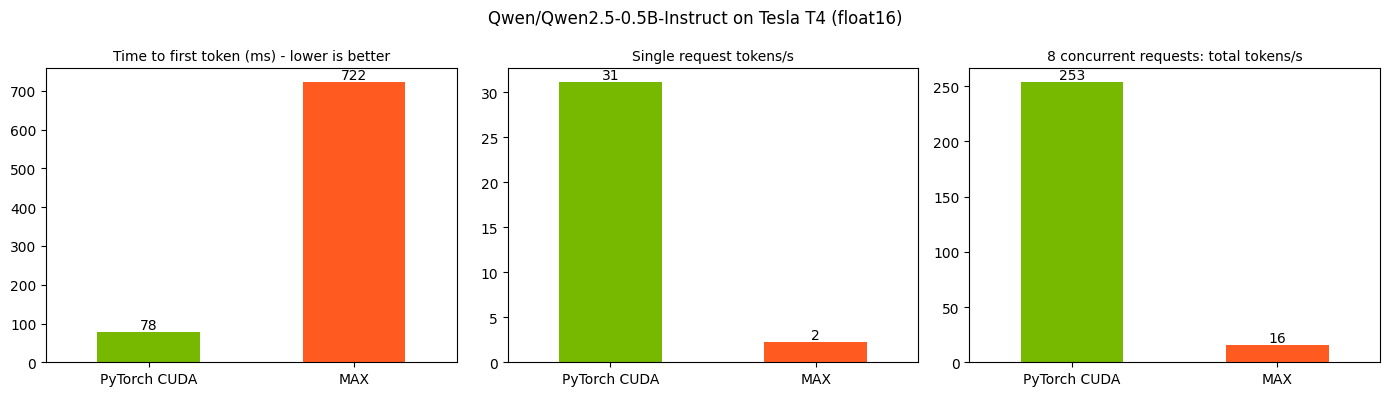

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(RESULTS).T
bk = f"batch{BATCH}_tok_s"
df = df[["ttft_ms", "single_tok_s", bk, "gpu_mem_gb"]].round(2)
display(df)

speed = {
    "TTFT speedup (x, lower latency is better)": df.loc["PyTorch CUDA","ttft_ms"] / df.loc["MAX","ttft_ms"],
    "Single-stream speedup (x)": df.loc["MAX","single_tok_s"] / df.loc["PyTorch CUDA","single_tok_s"],
    f"Batch-{BATCH} throughput speedup (x)": df.loc["MAX",bk] / df.loc["PyTorch CUDA",bk],
}
for k, v in speed.items(): print(f"{k}: {v:.2f}x")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col, title in zip(ax, ["ttft_ms", "single_tok_s", bk],
                         ["Time to first token (ms) - lower is better", "Single request tokens/s", f"{BATCH} concurrent requests: total tokens/s"]):
    df[col].plot.bar(ax=a, color=["#76b900", "#ff5a1f"], rot=0)
    a.set_title(title, fontsize=10)
    for i, v in enumerate(df[col]): a.text(i, v, f"{v:,.0f}", ha="center", va="bottom")
fig.suptitle(f"{MODEL} on {GPU_NAME} ({DTYPE_NAME})")
plt.tight_layout(); plt.show()

with open("benchmark_results.json", "w") as f:
    json.dump({"model": MODEL, "gpu": GPU_NAME, "dtype": DTYPE_NAME, "results": RESULTS}, f, indent=2)

In [13]:
# Cleanup: stop the MAX server
server.terminate()
try: server.wait(timeout=30)
except Exception: server.kill()
print("MAX server stopped.")

MAX server stopped.


### Notes on interpreting the results
- **Not a pure kernel comparison.** Part 1 is Hugging Face `generate()` (eager PyTorch on CUDA); Part 2 is the full MAX serving stack (graph compiler, continuous batching, paged KV cache). The gap reflects the whole stack, not just Mojo vs CUDA kernels. For a tougher CUDA baseline, swap Part 1 for vLLM or TensorRT-LLM.
- MAX pre-allocates GPU memory for its KV cache, so its memory number will look larger.
- If `max serve` flags have changed in your installed version, run `!{VENV}/bin/max serve --help`.
- Run the notebook more than once; first runs include download and compile time (excluded from the timings by the warmup).